In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


/kaggle/input/competitions/avazu-ctr-prediction/sampleSubmission.gz
/kaggle/input/competitions/avazu-ctr-prediction/train.gz
/kaggle/input/competitions/avazu-ctr-prediction/test.gz


In [2]:
import random
num_record = 40428967
sample_size = 5000000
skip_value = sorted(random.sample(range(1,num_record),num_record-sample_size))
parse_date = lambda val: pd.to_datetime(val,format='%y%m%d%H')

train_data = pd.read_csv("/kaggle/input/competitions/avazu-ctr-prediction/train.gz",
                         nrows = 1000000) #,skiprows=skip_value)

In [3]:
train_data['hour'] = pd.to_datetime(train_data['hour'],format='%y%m%d%H')
train_data.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21
0,1.000009e+18,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,2,15706,320,50,1722,0,35,-1,79
1,1.000017e+19,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,0,15704,320,50,1722,0,35,100084,79
2,1.000037e+19,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,0,15704,320,50,1722,0,35,100084,79
3,1.000064e+19,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,0,15706,320,50,1722,0,35,100084,79
4,1.000068e+19,0,2014-10-21,1005,1,fe8cc448,9166c161,0569f928,ecad2386,7801e8d9,...,1,0,18993,320,50,2161,0,35,-1,157


In [4]:
train_data.shape

(1000000, 24)

In [5]:
train_data['month'] = train_data['hour'].dt.month
train_data['dayofweek'] = train_data['hour'].dt.dayofweek
train_data['day'] = train_data['hour'].dt.day
train_data['hour_time'] = train_data['hour'].dt.hour

In [6]:
train_data.describe()

,id,click,hour,C1,banner_pos,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21,month,dayofweek,day,hour_time
count,1.000000e+06,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.0,1000000.0,1000000.0,1000000.000000
mean,9.376314e+18,0.160219,2014-10-21 02:34:52.924800768,1005.088166,0.229922,1.025540,0.223363,18262.203151,318.965808,56.495546,2041.031112,1.452262,190.779388,45505.857239,69.936118,10.0,1.0,21.0,2.581368
min,9.984920e+12,0.000000,2014-10-21 00:00:00,1001.000000,0.000000,0.000000,0.000000,375.000000,120.000000,20.000000,112.000000,0.000000,33.000000,-1.000000,13.000000,10.0,1.0,21.0,0.000000
25%,4.846660e+18,0.000000,2014-10-21 01:00:00,1005.000000,0.000000,1.000000,0.000000,15707.000000,320.000000,50.000000,1722.000000,0.000000,35.000000,-1.000000,43.000000,10.0,1.0,21.0,1.000000
50%,9.834387e+18,0.000000,2014-10-21 03:00:00,1005.000000,0.000000,1.000000,0.000000,19251.000000,320.000000,50.000000,2161.000000,1.000000,39.000000,-1.000000,61.000000,10.0,1.0,21.0,3.000000
75%,1.373053e+19,0.000000,2014-10-21 04:00:00,1005.000000,0.000000,1.000000,0.000000,21153.000000,320.000000,50.000000,2420.000000,3.000000,297.000000,100084.000000,79.000000,10.0,1.0,21.0,4.000000
max,1.844670e+19,1.000000,2014-10-21 05:00:00,1012.000000,7.000000,5.000000,5.000000,21705.000000,1024.000000,1024.000000,2497.000000,3.000000,1835.000000,100248.000000,195.000000,10.0,1.0,21.0,5.000000
std,5.236908e+18,0.366809,NaN,1.156928,0.464627,0.453899,0.667164,3510.366302,19.452897,36.546944,441.200965,1.362637,273.439286,49843.810147,38.513846,0.0,0.0,0.0,1.493256


In [7]:
test_data = pd.read_csv("/kaggle/input/competitions/avazu-ctr-prediction/test.gz")
test_data.head()

,id,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,...,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21
0,1.000017e+19,14103100,1005,0,235ba823,f6ebf28e,f028772b,ecad2386,7801e8d9,07d7df22,...,1,0,8330,320,50,761,3,175,100075,23
1,1.000018e+19,14103100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,...,1,0,22676,320,50,2616,0,35,100083,51
2,1.000055e+19,14103100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,...,1,0,22676,320,50,2616,0,35,100083,51
3,1.000109e+19,14103100,1005,0,85f751fd,c4e18dd6,50e219e0,51cedd4e,aefc06bd,0f2161f8,...,1,0,18648,320,50,1092,3,809,100156,61
4,1.000138e+19,14103100,1005,0,85f751fd,c4e18dd6,50e219e0,9c13b419,2347f47a,f95efa07,...,1,0,23160,320,50,2667,0,47,-1,221


In [8]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 28 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   id                1000000 non-null  float64       
 1   click             1000000 non-null  int64         
 2   hour              1000000 non-null  datetime64[ns]
 3   C1                1000000 non-null  int64         
 4   banner_pos        1000000 non-null  int64         
 5   site_id           1000000 non-null  object        
 6   site_domain       1000000 non-null  object        
 7   site_category     1000000 non-null  object        
 8   app_id            1000000 non-null  object        
 9   app_domain        1000000 non-null  object        
 10  app_category      1000000 non-null  object        
 11  device_id         1000000 non-null  object        
 12  device_ip         1000000 non-null  object        
 13  device_model      1000000 non-null  object 

In [9]:
type(train_data['app_id'][0])

str

In [10]:
train_data.isnull().sum()

id                  0
click               0
hour                0
C1                  0
banner_pos          0
site_id             0
site_domain         0
site_category       0
app_id              0
app_domain          0
app_category        0
device_id           0
device_ip           0
device_model        0
device_type         0
device_conn_type    0
C14                 0
C15                 0
C16                 0
C17                 0
C18                 0
C19                 0
C20                 0
C21                 0
month               0
dayofweek           0
day                 0
hour_time           0
dtype: int64

In [11]:
# 处理异常的数据
col = ['C15', 'C16', 'C19', 'C21']
for i in col:
    quantile = train_data[i].quantile(0.98)
    if quantile <= train_data[i].max() * 0.5:
        train_data[i] = train_data[i].clip(upper=quantile)

In [12]:
numerical_columns = []
categorical_columns = []
for column in train_data.columns:
    if train_data[column].dtype == 'object':
        categorical_columns.append(column)
    else:
        numerical_columns.append(column)
print("numerical_columns:",numerical_columns)
print("\ncate_gorical:",categorical_columns)

numerical_columns: ['id', 'click', 'hour', 'C1', 'banner_pos', 'device_type', 'device_conn_type', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'month', 'dayofweek', 'day', 'hour_time']

cate_gorical: ['site_id', 'site_domain', 'site_category', 'app_id', 'app_domain', 'app_category', 'device_id', 'device_ip', 'device_model']


In [13]:
train_data["click"].value_counts()

click
0    839781
1    160219
Name: count, dtype: int64

In [14]:
print("unique count of the site_id:",len(train_data['site_id'].unique()))
print(train_data['site_id'].value_counts(normalize = True))

unique count of the site_id: 2075
site_id
85f751fd    0.332893
1fbe01fe    0.232096
d9750ee7    0.038603
e151e245    0.032359
5b08c53b    0.016455
              ...   
9e293f11    0.000001
0b665712    0.000001
8ddfee4e    0.000001
08d892c7    0.000001
e229b1e4    0.000001
Name: proportion, Length: 2075, dtype: float64


In [15]:
print("unique count of the site_domain:",len(train_data['site_domain'].unique()))
print(train_data['site_domain'].value_counts(normalize = True))

unique count of the site_domain: 2030
site_domain
c4e18dd6    0.348412
f3845767    0.232096
98572c79    0.041031
7e091613    0.033718
7687a86e    0.023775
              ...   
3c515be1    0.000001
a88783c1    0.000001
7590586d    0.000001
9b95a528    0.000001
8ec3cd7e    0.000001
Name: proportion, Length: 2030, dtype: float64


In [16]:
print("unique count of the site_category:",len(train_data['site_category'].unique()))
print(train_data['site_category'].value_counts(normalize = True))

unique count of the site_category: 21
site_category
50e219e0    0.360056
28905ebd    0.262519
f028772b    0.260471
3e814130    0.075062
f66779e6    0.008842
76b2941d    0.007880
335d28a8    0.007251
70fb0e29    0.004961
0569f928    0.004505
75fa27f6    0.003958
72722551    0.002705
c0dd3be3    0.000552
dedf689d    0.000508
a818d37a    0.000374
e787de0e    0.000281
bcf865d9    0.000025
8fd0aea4    0.000022
42a36e14    0.000013
5378d028    0.000010
9ccfa2ea    0.000004
110ab22d    0.000001
Name: proportion, dtype: float64


In [17]:
print("unique count of the app_id:",len(train_data['app_id'].unique()))
print(train_data['app_id'].value_counts(normalize = True))

unique count of the app_id: 2309
app_id
ecad2386    0.667107
e2fcccd2    0.032263
febd1138    0.024725
54c5d545    0.012027
9c13b419    0.011481
              ...   
223a3f79    0.000001
ea1e1465    0.000001
afdf3311    0.000001
ccb710ac    0.000001
9f0f6f9a    0.000001
Name: proportion, Length: 2309, dtype: float64


In [18]:
print("unique count of the app_domain:",len(train_data['app_domain'].unique()))
print(train_data['app_domain'].value_counts(normalize = True))

unique count of the app_domain: 156
app_domain
7801e8d9    0.707429
2347f47a    0.140069
d9b5648e    0.040779
5c5a694b    0.032263
82e27996    0.024726
              ...   
f75ccedd    0.000001
916026d9    0.000001
e51135b7    0.000001
9299777a    0.000001
1cbecd39    0.000001
Name: proportion, Length: 156, dtype: float64


In [19]:
print("unique count of the app_category:",len(train_data['app_category'].unique()))
print(train_data['app_category'].value_counts(normalize = True))

unique count of the app_category: 23
app_category
07d7df22    0.679869
0f2161f8    0.225789
8ded1f7a    0.029806
f95efa07    0.028765
cef3e649    0.025260
d1327cf5    0.004302
fc6fa53d    0.001436
75d80bbe    0.001410
09481d60    0.001108
4ce2e9fc    0.000943
879c24eb    0.000373
dc97ec06    0.000367
a3c42688    0.000214
0f9a328c    0.000147
a86a3e89    0.000057
4681bb9d    0.000054
8df2e842    0.000031
2281a340    0.000025
0bfbc358    0.000014
7113d72a    0.000013
a7fd01ec    0.000011
79f0b860    0.000004
18b1e0be    0.000002
Name: proportion, dtype: float64


In [20]:
print("unique count of the device_id:",len(train_data['device_id'].unique()))
print(train_data['device_id'].value_counts(normalize = True))

unique count of the device_id: 83431
device_id
a99f214a    0.840265
c357dbff    0.001310
936e92fb    0.000482
31da1bd0    0.000292
787d2bb0    0.000274
              ...   
b884b3c1    0.000001
6c171e38    0.000001
e8f03f0c    0.000001
1eba2077    0.000001
2f7f62e6    0.000001
Name: proportion, Length: 83431, dtype: float64


In [21]:
print("unique counts of device_ip", len(train_data['device_ip'].unique()))
print(train_data['device_ip'].value_counts(normalize = True))

unique counts of device_ip 313002
device_ip
6b9769f2    0.005886
431b3174    0.003208
1cf29716    0.002386
ddd2926e    0.002377
ceffea69    0.002370
              ...   
c1dd1512    0.000001
32aa4ba8    0.000001
01765d63    0.000001
0d578673    0.000001
c05da1b7    0.000001
Name: proportion, Length: 313002, dtype: float64


In [22]:
print("unique counts of device_model", len(train_data['device_model'].unique()))
print(train_data['device_model'].value_counts(normalize = True))

unique counts of device_model 4581
device_model
8a4875bd    0.059771
d787e91b    0.042206
1f0bc64f    0.037525
4ea23a13    0.019853
a0f5f879    0.017158
              ...   
34555df1    0.000001
bd4811b9    0.000001
10baffd5    0.000001
931ea9e4    0.000001
85e0d06b    0.000001
Name: proportion, Length: 4581, dtype: float64


In [23]:
train_data['C20'].value_counts(normalize = True)

C20
-1         0.545390
 100111    0.095626
 100084    0.075248
 100083    0.031234
 100077    0.027020
             ...   
 100246    0.000003
 100169    0.000001
 100078    0.000001
 100059    0.000001
 100132    0.000001
Name: proportion, Length: 161, dtype: float64

In [24]:
train_data.drop(['month','C20'],axis=1,inplace = True)
train_data.columns

Index(['id', 'click', 'hour', 'C1', 'banner_pos', 'site_id', 'site_domain',
       'site_category', 'app_id', 'app_domain', 'app_category', 'device_id',
       'device_ip', 'device_model', 'device_type', 'device_conn_type', 'C14',
       'C15', 'C16', 'C17', 'C18', 'C19', 'C21', 'dayofweek', 'day',
       'hour_time'],
      dtype='object')

In [25]:
train_data.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,C14,C15,C16,C17,C18,C19,C21,dayofweek,day,hour_time
0,1.000009e+18,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,15706,320,50,1722,0,35,79,1,21,0
1,1.000017e+19,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,15704,320,50,1722,0,35,79,1,21,0
2,1.000037e+19,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,15704,320,50,1722,0,35,79,1,21,0
3,1.000064e+19,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,15706,320,50,1722,0,35,79,1,21,0
4,1.000068e+19,0,2014-10-21,1005,1,fe8cc448,9166c161,0569f928,ecad2386,7801e8d9,...,18993,320,50,2161,0,35,157,1,21,0


In [26]:
train_data.drop(['id','hour'],axis=1,inplace=True)
train_data.rename(columns={'click':'y','hour_time':'hour'},inplace=True)
train_data.columns

Index(['y', 'C1', 'banner_pos', 'site_id', 'site_domain', 'site_category',
       'app_id', 'app_domain', 'app_category', 'device_id', 'device_ip',
       'device_model', 'device_type', 'device_conn_type', 'C14', 'C15', 'C16',
       'C17', 'C18', 'C19', 'C21', 'dayofweek', 'day', 'hour'],
      dtype='object')

In [27]:
X = train_data.drop(['y'],axis=1)
y = train_data['y']

In [28]:
# 目标编码使用于高基数属性
# 使用目标编码的方式 去替换类别属性 

import category_encoders as ce
target_encoder = ce.TargetEncoder()
X = target_encoder.fit_transform(X,y)
X.head()

,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,C14,C15,C16,C17,C18,C19,C21,dayofweek,day,hour
0,1005,0,0.216143,0.216143,0.206351,0.191975,0.185569,0.190348,0.169408,0.225915,...,15706,320,50,1722,0,35,79,1,21,0
1,1005,0,0.216143,0.216143,0.206351,0.191975,0.185569,0.190348,0.169408,0.278881,...,15704,320,50,1722,0,35,79,1,21,0
2,1005,0,0.216143,0.216143,0.206351,0.191975,0.185569,0.190348,0.169408,0.137492,...,15704,320,50,1722,0,35,79,1,21,0
3,1005,0,0.216143,0.216143,0.206351,0.191975,0.185569,0.190348,0.169408,0.186959,...,15706,320,50,1722,0,35,79,1,21,0
4,1005,1,0.030655,0.030655,0.029301,0.191975,0.185569,0.190348,0.169408,0.040013,...,18993,320,50,2161,0,35,157,1,21,0


In [29]:
from sklearn.model_selection import train_test_split
train_x,test_x,train_y,test_y =train_test_split(X,y,test_size=0.3,random_state=42)

In [30]:
from sklearn import metrics
def model_eval(model,X,y):
    y_predict = model.predict(X)
    accuracy = metrics.accuracy_score(y,y_predict)
    confusion_matrix = metrics.confusion_matrix(y,y_predict)
    # print(f"mean_absolute_error:{metrics.mean_absolute_error(y,y_predict)}")
    # print(f"accuracy:{accuracy}")
    # print(f"confusion_matrix:{confusion_matrix}")
    return accuracy,confusion_matrix

In [31]:
# Plots the ROC curve and returns false positive rate, true positive rate, and thresholds. 
import matplotlib.pyplot as plt

def draw_roc(model, X_test, actual):
    probs = model.predict_proba(X_test)[:,1]
    fpr, tpr, thresholds = metrics.roc_curve( actual, probs,
                                              drop_intermediate = False )
    auc_score = metrics.roc_auc_score( actual, probs )
    plt.figure(figsize=(6, 6))
    plt.plot( fpr, tpr, label='ROC curve (area = %0.2f)' % auc_score )
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver operating characteristic example')
    plt.legend(loc="lower right")
    plt.show()

    return fpr, tpr, thresholds

In [32]:
from sklearn.model_selection import cross_val_score

def cross_val(model,X,y,folds):
    crossValidation = cross_val_score(model,X,y,cv = folds,n_jobs=1)
    return crossValidation

In [33]:
# this stores the results in dataframe for evaluating the final result. 

def store_results(name, ytrain, xtrain, ytest, xtest, model, folds):
    
    crossvalidation = cross_val(model, xtrain, ytrain, folds)
    
    accuracy_test, cm1 =  model_eval(model, xtrain, ytrain)
    TP = cm1[1,1] # true positive 
    TN = cm1[0,0] # true negatives
    FP = cm1[0,1] # false positives
    FN = cm1[1,0] # false negatives
    recall_test = TP / (TP+FP)
    precision_test = TP / (TP+FN)
    
    accuracy_train, cm1 =  model_eval(model, xtest, ytest)
    TP = cm1[1,1] # true positive 
    TN = cm1[0,0] # true negatives
    FP = cm1[0,1] # false positives
    FN = cm1[1,0] # false negatives
    recall_train = TP / (TP+FP)
    precision_train = TP / (TP+FN)

    entry = {'Model': [name],
          'Accuracy_train': [accuracy_train],
          'recall_train': [recall_train],
          'precision_train': [precision_train],
          'Accuracy_test': [accuracy_train],
          'recall_test': [recall_train],
          'precision_test': [precision_train],
          'CrossVal_Mean': [crossvalidation.mean()],           
          'CrossVal1': [crossvalidation[0]],
          'CrossVal2': [crossvalidation[1]],
          'CrossVal3': [crossvalidation[2]],
          'CrossVal4': [crossvalidation[3]],
          'CrossVal5': [crossvalidation[4]],
          }
    result = pd.DataFrame(entry)
    return result

In [34]:
from sklearn.dummy import DummyClassifier

outcome = pd.DataFrame()
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(train_x,train_y)
accuracy,confusion_matrix = model_eval(dummy_clf,train_x,train_y)
print(accuracy)
print(confusion_matrix)
temp = store_results("Dummy_classifier",train_y,train_x,test_y,test_x,dummy_clf,5)
outcome = pd.concat([outcome,temp])
outcome

0.8397471428571428
[[587823      0]
 [112177      0]]


/tmp/ipykernel_16/2240414290.py:12: RuntimeWarning: invalid value encountered in scalar divide
  recall_test = TP / (TP+FP)
/tmp/ipykernel_16/2240414290.py:20: RuntimeWarning: invalid value encountered in scalar divide
  recall_train = TP / (TP+FP)


,Model,Accuracy_train,recall_train,precision_train,Accuracy_test,recall_test,precision_test,CrossVal_Mean,CrossVal1,CrossVal2,CrossVal3,CrossVal4,CrossVal5
0,Dummy_classifier,0.83986,NaN,0.0,0.83986,NaN,0.0,0.839747,0.839743,0.839743,0.83975,0.83975,0.83975


In [35]:
train_y.value_counts(normalize=True)

y
0    0.839747
1    0.160253
Name: proportion, dtype: float64

### 基本回归模型

#### 带不平衡预估器的回归

In [36]:
train_x.head()

,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,C14,C15,C16,C17,C18,C19,C21,dayofweek,day,hour
506532,1005,0,0.096581,0.100212,0.106383,0.129376,0.119988,0.102605,0.169408,0.208417,...,21611,320,50,2480,3,299,61,1,21,3
327991,1005,0,0.096581,0.100212,0.106383,0.040157,0.185569,0.102605,0.139373,0.139373,...,21647,320,50,2487,1,547,51,1,21,2
715937,1005,0,0.096581,0.100212,0.106383,0.232036,0.092412,0.142639,0.169408,0.139373,...,19251,320,50,2201,3,35,43,1,21,4
860726,1005,0,0.096581,0.100212,0.106383,0.061708,0.119988,0.102605,0.169408,0.137492,...,20277,320,50,2281,3,47,42,1,21,4
78617,1005,0,0.096581,0.100212,0.106383,0.044975,0.044973,0.102605,0.169408,0.117129,...,19743,320,50,2264,3,427,61,1,21,0


In [37]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler() # 将数据映射到 0-1 之间
# train_x[train_x.columns] = scaler.fit_transform(train_x[train_x.columns])
train_x_scaler = scaler.fit_transform(train_x)
train_x = pd.DataFrame(train_x_scaler,columns=train_x.columns,index=train_x.index)
train_x.head()

,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,C14,C15,C16,C17,C18,C19,C21,dayofweek,day,hour
506532,0.363636,0.0,0.142697,0.148062,0.476766,0.131308,0.429515,0.445535,0.281837,0.294279,...,0.995593,1.0,0.130435,0.992872,1.000000,0.147614,0.263736,0.0,0.0,0.6
327991,0.363636,0.0,0.142697,0.148062,0.476766,0.040756,0.664293,0.445535,0.231869,0.196791,...,0.997281,1.0,0.130435,0.995807,0.333333,0.285239,0.208791,0.0,0.0,0.4
715937,0.363636,0.0,0.142697,0.148062,0.476766,0.235501,0.330792,0.639075,0.281837,0.196791,...,0.884951,1.0,0.130435,0.875891,1.000000,0.001110,0.164835,0.0,0.0,0.8
860726,0.363636,0.0,0.142697,0.148062,0.476766,0.062629,0.429515,0.445535,0.281837,0.194134,...,0.933052,1.0,0.130435,0.909434,1.000000,0.007769,0.159341,0.0,0.0,0.8
78617,0.363636,0.0,0.142697,0.148062,0.476766,0.045646,0.160963,0.445535,0.281837,0.165383,...,0.908017,1.0,0.130435,0.902306,1.000000,0.218646,0.263736,0.0,0.0,0.0


In [38]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(train_x,train_y)

LogisticRegression()

In [39]:
test_x[test_x.columns] = scaler.transform(test_x[test_x.columns])
test_x.head()

,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,C14,C15,C16,C17,C18,C19,C21,dayofweek,day,hour
987231,0.363636,0.000000,0.142697,0.148062,0.476766,0.089466,0.330792,0.445535,0.281837,0.026967,...,0.998218,1.0,0.130435,0.998742,1.0,0.001110,0.543956,0.0,0.0,1.0
79954,0.363636,0.000000,0.319349,0.319349,0.924778,0.194842,0.664293,0.869724,0.281837,0.194134,...,0.718659,1.0,0.130435,0.675052,0.0,0.001110,0.362637,0.0,0.0,0.0
567130,0.363636,0.142857,0.089335,0.089335,0.823223,0.194842,0.664293,0.869724,0.281837,0.129953,...,0.742288,1.0,0.130435,0.707757,1.0,0.074362,0.054945,0.0,0.0,0.6
500891,0.363636,0.000000,0.142697,0.148062,0.476766,0.021723,0.330792,0.238048,0.231869,0.176354,...,0.884951,1.0,0.130435,0.875891,1.0,0.001110,0.164835,0.0,0.0,0.6
55399,0.363636,0.000000,0.142697,0.148062,0.476766,0.524649,0.330792,0.238048,0.448324,0.380500,...,0.000094,1.0,0.130435,0.000000,1.0,0.713651,0.010989,0.0,0.0,0.0


In [40]:
temp = store_results("LogisticRegression - imbalanced predict",train_y,train_x,test_y,test_x,model,5)
outcome = pd.concat([outcome,temp])
outcome

,Model,Accuracy_train,recall_train,precision_train,Accuracy_test,recall_test,precision_test,CrossVal_Mean,CrossVal1,CrossVal2,CrossVal3,CrossVal4,CrossVal5
0,Dummy_classifier,0.839860,NaN,0.000000,0.839860,NaN,0.000000,0.839747,0.839743,0.839743,0.839750,0.839750,0.839750
0,LogisticRegression - imbalanced predict,0.870103,0.656967,0.395217,0.870103,0.656967,0.395217,0.870959,0.871100,0.870993,0.870714,0.870793,0.871193


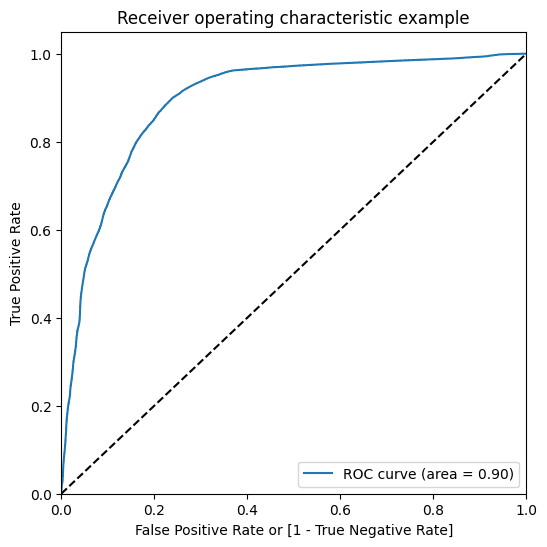

(array([0.        , 0.        , 0.        , ..., 0.99995634, 0.99998016,
        1.        ]),
 array([0.00000000e+00, 1.66520961e-04, 1.87336081e-04, ...,
        1.00000000e+00, 1.00000000e+00, 1.00000000e+00]),
 array([           inf, 9.99999999e-01, 9.99999999e-01, ...,
        1.22815942e-05, 1.22808300e-05, 1.22789197e-05]))

In [41]:
draw_roc(model,test_x,test_y)

#### 带平衡预估器的回归模型

In [42]:
from imblearn.over_sampling import RandomOverSampler
randomOverSample = RandomOverSampler()
X_new,y_new = randomOverSample.fit_resample(X,y)
y_new.value_counts()

y
0    839781
1    839781
Name: count, dtype: int64

In [43]:
train_x,test_x,train_y,test_y = train_test_split(X_new,y_new,
                                                 stratify=y_new,test_size=0.3,random_state=42)

In [44]:
scaler = MinMaxScaler()
train_x_scaler = scaler.fit_transform(train_x)
test_x_scaler = scaler.transform(test_x)
train_x = pd.DataFrame(train_x_scaler,columns=train_x.columns,index=train_x.index)
test_x = pd.DataFrame(test_x_scaler,columns=test_x.columns,index=test_x.index)
#train_x.head()
test_x.head()

,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,C14,C15,C16,C17,C18,C19,C21,dayofweek,day,hour
1164826,0.363636,0.142857,0.641700,0.620652,0.823223,0.194842,0.664293,0.869724,0.281837,0.380500,...,0.808204,1.0,0.130435,0.788679,0.666667,0.571587,0.109890,0.0,0.0,0.0
111092,0.363636,0.000000,0.319349,0.319349,0.924778,0.194842,0.664293,0.869724,0.281837,0.305291,...,0.718847,1.0,0.130435,0.675052,0.000000,0.001110,0.362637,0.0,0.0,0.0
1357314,0.363636,0.000000,0.319349,0.319349,0.924778,0.194842,0.664293,0.869724,0.281837,0.413657,...,0.718800,1.0,0.130435,0.675052,0.000000,0.001110,0.362637,0.0,0.0,0.8
1525053,0.363636,0.000000,0.142697,0.148062,0.476766,0.045646,0.160963,0.445535,0.281837,0.380500,...,0.933052,1.0,0.130435,0.909434,1.000000,0.007769,0.159341,0.0,0.0,0.6
1046519,0.363636,0.142857,0.406093,0.395291,0.823223,0.194842,0.664293,0.869724,0.281837,0.316367,...,0.806751,1.0,0.130435,0.787841,0.666667,0.003330,0.109890,0.0,0.0,0.2


In [45]:
model = LogisticRegression()
model.fit(train_x,train_y)

LogisticRegression()

In [46]:
outcome

,Model,Accuracy_train,recall_train,precision_train,Accuracy_test,recall_test,precision_test,CrossVal_Mean,CrossVal1,CrossVal2,CrossVal3,CrossVal4,CrossVal5
0,Dummy_classifier,0.839860,NaN,0.000000,0.839860,NaN,0.000000,0.839747,0.839743,0.839743,0.839750,0.839750,0.839750
0,LogisticRegression - imbalanced predict,0.870103,0.656967,0.395217,0.870103,0.656967,0.395217,0.870959,0.871100,0.870993,0.870714,0.870793,0.871193


In [47]:
accuracy,confusion_matrix = model_eval(model,test_x,test_y)
print(accuracy)
print(confusion_matrix)
temp = store_results("LogisticRegression - balanced predict",train_y,train_x,test_y,test_x,model,5)
outcome
outcome = pd.concat([outcome,temp],ignore_index=True)

0.8247480992083259
[[207118  44817]
 [ 43487 208447]]


In [48]:
outcome

,Model,Accuracy_train,recall_train,precision_train,Accuracy_test,recall_test,precision_test,CrossVal_Mean,CrossVal1,CrossVal2,CrossVal3,CrossVal4,CrossVal5
0,Dummy_classifier,0.839860,NaN,0.000000,0.839860,NaN,0.000000,0.839747,0.839743,0.839743,0.839750,0.839750,0.839750
1,LogisticRegression - imbalanced predict,0.870103,0.656967,0.395217,0.870103,0.656967,0.395217,0.870959,0.871100,0.870993,0.870714,0.870793,0.871193
2,LogisticRegression - balanced predict,0.824748,0.823042,0.827387,0.824748,0.823042,0.827387,0.824804,0.824096,0.825699,0.824346,0.825111,0.824767


### 带有不平衡数据的决策树分类器

In [49]:
train_x,test_x,train_y,test_y = train_test_split(X,y,stratify=y,test_size=0.3,random_state=42)

In [50]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(train_x,train_y)

DecisionTreeClassifier(random_state=42)

In [51]:
accuracy,confusion_matrix = model_eval(model,test_x,test_y)
print(accuracy)
print(confusion_matrix)
temp=store_results("DecisionTreeClassifier - imbalanced data",train_y,train_x,test_y,test_x,model,5)
outcome=pd.concat([outcome,temp],ignore_index=True)

0.8686566666666666
[[235106  16828]
 [ 22575  25491]]


In [52]:
outcome

,Model,Accuracy_train,recall_train,precision_train,Accuracy_test,recall_test,precision_test,CrossVal_Mean,CrossVal1,CrossVal2,CrossVal3,CrossVal4,CrossVal5
0,Dummy_classifier,0.839860,NaN,0.000000,0.839860,NaN,0.000000,0.839747,0.839743,0.839743,0.839750,0.839750,0.839750
1,LogisticRegression - imbalanced predict,0.870103,0.656967,0.395217,0.870103,0.656967,0.395217,0.870959,0.871100,0.870993,0.870714,0.870793,0.871193
2,LogisticRegression - balanced predict,0.824748,0.823042,0.827387,0.824748,0.823042,0.827387,0.824804,0.824096,0.825699,0.824346,0.825111,0.824767
3,DecisionTreeClassifier - imbalanced data,0.868657,0.602354,0.530333,0.868657,0.602354,0.530333,0.866974,0.866836,0.866607,0.866443,0.867879,0.867107


### 带有平衡数据的决策树分类器

In [53]:
randomOverSample = RandomOverSampler()
X_new,y_new = randomOverSample.fit_resample(X,y)

In [54]:
train_x,test_x,train_y,test_y = train_test_split(X_new,y_new,stratify=y_new,
                                                 test_size=0.3,random_state=42)

In [55]:
model = DecisionTreeClassifier(random_state=42)
model.fit(train_x,train_y)

DecisionTreeClassifier(random_state=42)

In [56]:
accuracy,confusion_matrix = model_eval(model,test_x,test_y)
print(accuracy)
print(confusion_matrix)
temp = store_results("DecisionTreeClassifier - balanced data",train_y,train_x,test_y,test_x,model,5)
outcome
outcome = pd.concat([outcome,temp],ignore_index=True)

0.9127332699570722
[[219739  32196]
 [ 11775 240159]]


In [57]:
outcome

,Model,Accuracy_train,recall_train,precision_train,Accuracy_test,recall_test,precision_test,CrossVal_Mean,CrossVal1,CrossVal2,CrossVal3,CrossVal4,CrossVal5
0,Dummy_classifier,0.839860,NaN,0.000000,0.839860,NaN,0.000000,0.839747,0.839743,0.839743,0.839750,0.839750,0.839750
1,LogisticRegression - imbalanced predict,0.870103,0.656967,0.395217,0.870103,0.656967,0.395217,0.870959,0.871100,0.870993,0.870714,0.870793,0.871193
2,LogisticRegression - balanced predict,0.824748,0.823042,0.827387,0.824748,0.823042,0.827387,0.824804,0.824096,0.825699,0.824346,0.825111,0.824767
3,DecisionTreeClassifier - imbalanced data,0.868657,0.602354,0.530333,0.868657,0.602354,0.530333,0.866974,0.866836,0.866607,0.866443,0.867879,0.867107
4,DecisionTreeClassifier - balanced data,0.912733,0.881787,0.953262,0.912733,0.881787,0.953262,0.902915,0.902568,0.903121,0.903593,0.902857,0.902436


#### 带不平衡数据的随机森林分类器

In [58]:
from sklearn.ensemble import RandomForestClassifier

In [59]:
train_x,test_x,train_y,test_y = train_test_split(X,y,test_size=0.3,random_state=42)

In [60]:
model = RandomForestClassifier(random_state=42)
model.fit(train_x,train_y)

RandomForestClassifier(random_state=42)

In [61]:
accuracy,confusion_matrix = model_eval(model,test_x,test_y)
print(accuracy)
print(confusion_matrix)
temp = store_results("RandomForestClassifier - imbalanced data",train_y,train_x,test_y,test_x,model,5)
outcome = pd.concat([outcome,temp],ignore_index=True)

0.8754433333333334
[[237291  14667]
 [ 22700  25342]]


In [62]:
outcome

,Model,Accuracy_train,recall_train,precision_train,Accuracy_test,recall_test,precision_test,CrossVal_Mean,CrossVal1,CrossVal2,CrossVal3,CrossVal4,CrossVal5
0,Dummy_classifier,0.839860,NaN,0.000000,0.839860,NaN,0.000000,0.839747,0.839743,0.839743,0.839750,0.839750,0.839750
1,LogisticRegression - imbalanced predict,0.870103,0.656967,0.395217,0.870103,0.656967,0.395217,0.870959,0.871100,0.870993,0.870714,0.870793,0.871193
2,LogisticRegression - balanced predict,0.824748,0.823042,0.827387,0.824748,0.823042,0.827387,0.824804,0.824096,0.825699,0.824346,0.825111,0.824767
3,DecisionTreeClassifier - imbalanced data,0.868657,0.602354,0.530333,0.868657,0.602354,0.530333,0.866974,0.866836,0.866607,0.866443,0.867879,0.867107
4,DecisionTreeClassifier - balanced data,0.912733,0.881787,0.953262,0.912733,0.881787,0.953262,0.902915,0.902568,0.903121,0.903593,0.902857,0.902436
5,RandomForestClassifier - imbalanced data,0.875443,0.633407,0.527497,0.875443,0.633407,0.527497,0.875043,0.875986,0.874679,0.874407,0.874857,0.875286


#### 带平衡数据的随机森林

In [63]:
X_new,y_new = randomOverSample.fit_resample(X,y)
train_x,test_x,train_y,test_y = train_test_split(X_new,y_new,
                                                 stratify=y_new,test_size=0.3,random_state=42)
train_x.head()

,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,C14,C15,C16,C17,C18,C19,C21,dayofweek,day,hour
321428,1005,0,0.216143,0.216143,0.206351,0.191975,0.185569,0.190348,0.169408,0.137492,...,15705,320,50,1722,0,35,79,1,21,2
1007548,1005,0,0.216143,0.216143,0.206351,0.191975,0.185569,0.190348,0.169408,0.269482,...,15705,320,50,1722,0,35,79,1,21,2
1492737,1005,0,0.460273,0.485762,0.223136,0.191975,0.185569,0.190348,0.169408,0.257730,...,20016,300,250,2285,2,39,23,1,21,2
1260654,1005,0,0.216143,0.216143,0.206351,0.191975,0.185569,0.190348,0.169408,0.225760,...,15705,320,50,1722,0,35,79,1,21,1
358943,1005,0,0.126000,0.127110,0.183690,0.191975,0.185569,0.190348,0.169408,0.188131,...,21647,320,50,2487,1,547,51,1,21,2


In [64]:
model = RandomForestClassifier(random_state=42)
model.fit(train_x,train_y)

RandomForestClassifier(random_state=42)

In [65]:
accuracy,confusion_matrix = model_eval(model,test_x,test_y)
print(accuracy)
print(confusion_matrix)
temp = store_results("RandomForestClassifier - balanced data",train_y,train_x,test_y,test_x,model,5)
outcome = pd.concat([outcome,temp],ignore_index=True)

0.9138129156586335
[[217856  34079]
 [  9348 242586]]


In [66]:
outcome

,Model,Accuracy_train,recall_train,precision_train,Accuracy_test,recall_test,precision_test,CrossVal_Mean,CrossVal1,CrossVal2,CrossVal3,CrossVal4,CrossVal5
0,Dummy_classifier,0.839860,NaN,0.000000,0.839860,NaN,0.000000,0.839747,0.839743,0.839743,0.839750,0.839750,0.839750
1,LogisticRegression - imbalanced predict,0.870103,0.656967,0.395217,0.870103,0.656967,0.395217,0.870959,0.871100,0.870993,0.870714,0.870793,0.871193
2,LogisticRegression - balanced predict,0.824748,0.823042,0.827387,0.824748,0.823042,0.827387,0.824804,0.824096,0.825699,0.824346,0.825111,0.824767
3,DecisionTreeClassifier - imbalanced data,0.868657,0.602354,0.530333,0.868657,0.602354,0.530333,0.866974,0.866836,0.866607,0.866443,0.867879,0.867107
4,DecisionTreeClassifier - balanced data,0.912733,0.881787,0.953262,0.912733,0.881787,0.953262,0.902915,0.902568,0.903121,0.903593,0.902857,0.902436
5,RandomForestClassifier - imbalanced data,0.875443,0.633407,0.527497,0.875443,0.633407,0.527497,0.875043,0.875986,0.874679,0.874407,0.874857,0.875286
6,RandomForestClassifier - balanced data,0.913813,0.876822,0.962895,0.913813,0.876822,0.962895,0.905166,0.906702,0.904384,0.905320,0.905073,0.904350


### 带特征工程的基本模型

In [67]:
data_feature = train_data.copy()
# according to pearson 
# C14 and C17 is relative
# device_type and C1 is relative
data_feature.drop(['C14','C1'],axis=1,inplace=True)

In [68]:
X = data_feature.drop(['y'],axis=1)
y = data_feature['y']

In [69]:
target_encoder = ce.TargetEncoder()
X = target_encoder.fit_transform(X,y)

In [70]:
randomOverSample = RandomOverSampler(random_state=42)
X_new,y_new = randomOverSample.fit_resample(X,y)

In [71]:
train_x,test_x,train_y,test_y = train_test_split(X_new,y_new,stratify=y_new,
                                                 test_size=0.3,random_state=42)

#### 带有平衡预估器和特征工程的逻辑回归

In [72]:
scaler = MinMaxScaler()
train_x[train_x.columns] = scaler.fit_transform(train_x[train_x.columns])
test_x[test_x.columns] = scaler.transform(test_x[test_x.columns])

In [73]:
import statsmodels.api as sm
train_x_sm = sm.add_constant(train_x)
logm2 = sm.GLM(train_y,train_x_sm,family=sm.families.Binomial())
res = logm2.fit()
res.summary()

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:              1175693
Model:                            GLM   Df Residuals:                  1175673
Model Family:                Binomial   Df Model:                           19
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -4.9022e+05
Date:                Fri, 13 Nov 2026   Deviance:                   9.8043e+05
Time:                        14:51:57   Pearson chi2:                 2.04e+08
No. Iterations:                     7   Pseudo R-squ. (CS):             0.4244
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -12.0181      0.071   -168.189      0.000     -12.158     -11.878
banner_pos           1.0074      0.048     21.061      0.000       0.914       1.101
site_id              0.0913      0.074      1.242      0.214      -0.053       0.235
site_domain          2.3742      0.078     30.555      0.000       2.222       2.526
site_category        0.6883      0.024     29.065      0.000       0.642       0.735
app_id               5.5523      0.074     75.227      0.000       5.408       5.697
app_domain          -1.0955      0.036    -30.525      0.000      -1.166      -1.025
app_category        -1.1069      0.031    -36.239      0.000      -1.167      -1.047
device_id           19.2947      0.143    135.078      0.000      19.015      19.575
device_ip           17.0713      0.037    459.711      0.000      16.999      17.144
device_model         0.4135      0.021     19.395      0.000       0.372       0.455
device_type          1.1254      0.046     24.571      0.000       1.036       1.215
device_conn_type    -0.2118      0.023     -9.036      0.000      -0.258      -0.166
C15                  0.4729      0.049      9.691      0.000       0.377       0.569
C16                  0.0318      0.019      1.709      0.087      -0.005       0.068
C17                 -0.1205      0.017     -7.110      0.000      -0.154      -0.087
C18                  0.3683      0.009     41.134      0.000       0.351       0.386
C19                  0.8249      0.019     42.924      0.000       0.787       0.863
C21                  0.8533      0.018     46.379      0.000       0.817       0.889
dayofweek                 0          0        nan        nan           0           0
day                       0          0        nan        nan           0           0
hour                 0.0098      0.009      1.118      0.264      -0.007       0.027
====================================================================================
"""

In [74]:
train_y_predict = res.predict(train_x_sm)
train_y_predict_final = pd.DataFrame({'y':train_y,'y_prob':train_y_predict})
train_y_predict_final['predict'] = train_y_predict_final.y_prob.map(lambda x: 1 if x>0.5 else 0)
confusion_matrix = metrics.confusion_matrix(train_y,train_y_predict_final.predict)
accuracy = metrics.accuracy_score(train_y,train_y_predict_final.predict)
print(confusion_matrix)
print(accuracy)

[[483680 104166]
 [101963 485884]]
0.8246744685900146


In [75]:
def sm_model_evaluation(model,test_x,test_y):
    test_x_sm = sm.add_constant(test_x,has_constant='add')
    test_y_predict = model.predict(test_x_sm)
    test_y_predict_final = pd.DataFrame({'y':test_y,'y_prob':test_y_predict})
    test_y_predict_final['predict']=test_y_predict_final.y_prob.map(lambda x:1 if x>0.5 else 0)
    confusion_matrix = metrics.confusion_matrix(test_y,test_y_predict_final.predict)
    accuracy = metrics.accuracy_score(test_y,test_y_predict_final.predict)
    print(confusion_matrix)
    print(accuracy)

In [76]:
#test_x[test_x.columns] = scaler.transform(test_x[test_x.columns])
#print(test_x.head())
sm_model_evaluation(res,test_x,test_y)

[[207117  44818]
 [ 43660 208274]]
0.8244027713552531


In [77]:
train_x_sm

,const,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,device_conn_type,C15,C16,C17,C18,C19,C21,dayofweek,day,hour
321428,1.0,0.000000,0.319349,0.319349,0.924778,0.194842,0.664293,0.869724,0.281837,0.194134,...,0.0,1.0,0.130435,0.675052,0.000000,0.001110,0.362637,0.0,0.0,0.4
1007548,1.0,0.000000,0.319349,0.319349,0.924778,0.194842,0.664293,0.869724,0.281837,0.494210,...,0.0,1.0,0.130435,0.675052,0.000000,0.001110,0.362637,0.0,0.0,0.6
1492737,1.0,0.000000,0.142697,0.148062,0.476766,0.128734,0.454043,0.639075,0.281837,0.119193,...,0.0,1.0,0.130435,0.859119,0.000000,0.001110,0.791209,0.0,0.0,0.2
1260654,1.0,0.142857,0.641700,0.620652,0.823223,0.194842,0.664293,0.869724,0.281837,0.233799,...,0.0,1.0,0.130435,0.675052,0.000000,0.001110,0.362637,0.0,0.0,0.0
358943,1.0,0.000000,0.186163,0.187804,0.823223,0.194842,0.664293,0.869724,0.281837,0.265635,...,0.0,1.0,0.130435,0.995807,0.333333,0.285239,0.208791,0.0,0.0,0.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1520202,1.0,0.142857,0.406093,0.395291,0.823223,0.194842,0.664293,0.869724,0.281837,0.325345,...,0.0,1.0,0.130435,0.931237,0.000000,0.003330,0.791209,0.0,0.0,0.4
913905,1.0,0.000000,0.319349,0.319349,0.924778,0.194842,0.664293,0.869724,0.281837,0.184955,...,0.0,1.0,0.130435,0.675052,0.000000,0.001110,0.362637,0.0,0.0,0.8
430340,1.0,0.000000,0.142697,0.148062,0.476766,0.140307,0.330792,0.445535,0.346734,0.294279,...,0.0,1.0,0.130435,0.995807,0.333333,0.285239,0.208791,0.0,0.0,0.4
1375048,1.0,0.000000,0.314320,0.314320,0.823223,0.194842,0.664293,0.869724,0.281837,0.380500,...,0.0,1.0,0.130435,0.749266,0.000000,0.220866,0.571429,0.0,0.0,1.0


In [78]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.DataFrame()
vif['Feature'] = train_x_sm.columns
vif['VIF'] = [variance_inflation_factor(train_x_sm.values,i) for i in range(train_x_sm.shape[1])]
vif['VIF'] = round(vif['VIF'],2)
vif = vif.sort_values(by = "VIF",ascending = False)
vif

/tmp/ipykernel_16/158670065.py:4: UserWarning: The design matrix is poorly conditioned (condition number=inf). VIF calculations may be numerically unstable.
  vif['VIF'] = [variance_inflation_factor(train_x_sm.values,i) for i in range(train_x_sm.shape[1])]
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-pack

,Feature,VIF
3,site_domain,19.11
2,site_id,18.09
7,app_category,4.91
6,app_domain,3.38
4,site_category,3.09
16,C18,2.25
18,C21,2.02
14,C16,1.81
5,app_id,1.77
1,banner_pos,1.52


In [79]:
model = LogisticRegression()
model.fit(train_x_sm,train_y)
accuracy,confusion_matrix = sm_model_evaluation(model,test_x[train_x.columns],test_y)
temp = store_results("logistic reg with feature engine",train_y,train_x_sm,
        test_y,test_x[train_x_sm.columns],model,5)
drow_roc(model,test_x[train_x_sm.columns],test_y)
outcome=pd.concat([outcom,temp])
outcome

[[207155  44780]
 [ 43682 208252]]
0.824434525640593


TypeError: cannot unpack non-iterable NoneType object

#### 带有特征工程和平衡预估器的随机森林

In [ ]:
train_x,test_x,train_y,test_y = train_test_split(X_new,y_new,stratify=y_new,test_size=0.3,random_state=42)

In [ ]:
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(train_x,train_y)
feature_importance = model_rf.feature_importances_
feature = train_x.columns
df = pd.DataFrame({'feature':feature,'feature_importance':feature_importance})
df.sort_values(by='feature_importance',ascending = False)

In [ ]:
df = df[df.feature_importance > 0.02]
rf_cols = []
for col in list(train_x.columns):
    if col in list(df.feature):
        rf_cols.append(col)

In [ ]:
new_train_x = train_x[rf_cols]
new_test_x = test_x[rf_cols]
model_rf.fit(new_train_x,train_y)
train_accuracy,train_confusion_matrix = model_eval(model_rf,new_train_x,train_y)
test_accuracy,test_confusion_matrix = model_eval(model_rf,new_test_x,test_y)
print(train_accuracy)
print(train_confusion_matrix)
print(test_accuracy)
print(test_confusion_matrix)

In [ ]:
temp = store_results("Random Forest with feature engine", train_y,new_train_x,test_y,new_test_x, \
                     model_rf, 5)
outcome = pd.concat([outcome,temp])

In [ ]:
outcome

### 提交结果

In [ ]:
test = pd.read_csv("/kaggle/input/competitions/avazu-ctr-prediction/test.gz")
test['hour'] = pd.to_datetime(test['hour'],format="%y%m%d%H")
test['month'] = test['hour'].dt.month
test['dayofweek'] = test['hour'].dt.dayofweek
test['day'] = test['hour'].dt.day
test['hour_time'] = test['hour'].dt.hour
test.head(2)

In [ ]:
col = ['C15', 'C16', 'C19', 'C21']
for col in col:
    percentiles = test[col].quantile(0.98)
    if test[col].quantile(0.98) < 0.5 * test[col].max():
        test.loc[test[col] >= percentiles, col] = percentiles

In [ ]:
test.drop(['id', 'hour'], axis = 1, inplace = True) 
test.rename(columns={'hour_time': 'hour'},
          inplace=True, errors='raise')
test.columns

In [ ]:
test.drop(['month', 'C20'], axis=1, inplace=True)
test.drop(['C14', 'C1'], axis=1, inplace= True)

In [ ]:
test =  target_encoder.transform(test)
test.head(2)

In [ ]:
test[test.columns]  = scaler.transform(test[test.columns])
test.head(2)

In [ ]:
rf_cols

In [ ]:
test = test[rf_cols]
predict_sub = model_rf.predict(test)
print(len(predict_sub))
print(predict_sub)

In [ ]:
submission = pd.DataFrame({})

In [ ]:
submission['click'] = predict_sub
submission.head(2)

In [ ]:
submission.to_csv('submission.csv', index = False)